# Geneation of features

In [31]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
from scipy import stats, signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

Idea: 
 - focus on a single user for now
  -  estimate parameters from the non-intensive activities time series
  - build a model to predict/impute values for the intensive activities  

- restrict to z axis?
- restrict to accelometer?

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
user_id = 1610

## Auxiliary features

In [12]:
idx_eat = phone_acc_df.loc[: , 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
df_eat = phone_acc_df.loc[idx_eat]

In [13]:
idx_act = phone_acc_df.loc[:, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
df_act = phone_acc_df.loc[idx_act]

### Means

<Axes: >

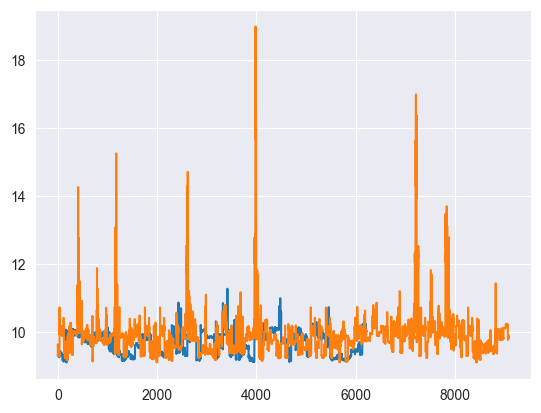

In [14]:
df_eat.reset_index()['RESULTANT'].plot()
df_act.reset_index()['RESULTANT'].plot()


In [15]:
eat_avgs  = df_eat.drop(columns="ACTIVITY").reset_index().groupby("class").mean()

In [21]:
act_avgs  = df_act.drop(columns="ACTIVITY").reset_index().groupby("class").mean()

`FIXME: what to do with the histogram features?`

In [16]:
eat_avgs

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,ZMFCC10,ZMFCC11,ZMFCC12,XYCOS,XZCOS,YZCOS,XYCOR,XZCOR,YZCOR,RESULTANT
class,,,,,,,,,,,,,,,,,,,,,
1600,0.000000,0.000112,0.604607,0.394944,0.000337,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.357745,0.353580,0.349036,0.995514,0.996987,0.998795,-0.274417,0.073085,-0.771238,9.331720
1601,0.444602,0.555044,0.000354,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.444904,0.439725,0.434074,-0.843814,-0.994534,0.847225,0.283265,0.206585,-0.046499,9.637117
1602,0.109786,0.889198,0.001016,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.438980,0.433869,0.428294,0.974565,-0.987472,-0.993046,-0.164261,0.109770,0.216951,9.217260
1603,0.000088,0.000088,0.000482,0.007544,0.434868,0.555658,0.001053,0.000132,0.000088,0.000000,...,0.366407,0.362142,0.357488,0.834449,0.994744,0.843306,-0.142009,-0.572555,0.028999,9.788542
1604,0.000000,0.000000,0.000056,0.401517,0.597809,0.000506,0.000000,0.000112,0.000000,0.000000,...,0.361698,0.357487,0.352893,0.995250,0.996765,0.996512,-0.286019,-0.220771,-0.396880,9.240737
1605,0.000000,0.000000,0.008009,0.159735,0.660265,0.170841,0.001150,0.000000,0.000000,0.000000,...,0.384267,0.379794,0.374913,0.576124,0.995803,0.569823,0.136351,-0.350887,-0.088930,9.755170
1606,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.132262,0.130722,0.129043,0.616682,0.673865,0.338299,-0.284824,-0.326761,0.199525,10.003064
1607,0.982912,0.005495,0.006648,0.004945,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.393725,0.389141,0.384141,-0.171046,0.487864,-0.685097,0.133292,-0.154104,0.172101,9.874274
1608,0.015647,0.283621,0.005172,0.218836,0.474440,0.002241,0.000043,0.000000,0.000000,0.000000,...,0.392694,0.388122,0.383135,0.929512,0.400443,0.462130,-0.330600,-0.071846,-0.210983,9.207354


### Peak means

In [17]:
scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)

(array([  52,  107,  152,  164,  242,  288,  319,  326,  399,  464,  583,
         761,  830,  940,  947,  953,  965,  976,  981,  983,  993,  995,
        1008, 1020, 1030, 1048, 1068, 1072, 1084, 1089, 1092, 1145, 1250,
        1305, 1428, 1483, 1581, 1706, 1761, 1832, 1854, 1895, 1924, 1981,
        2011, 2018, 2056, 2100, 2234, 2296, 2386, 2430, 2482, 2520, 2555,
        2632, 2744, 2771, 2777, 2878, 2953, 3146, 3165, 3182, 3236, 3325,
        3415, 3510, 3559, 3640, 3715, 3766, 3878, 3984, 4020, 4069, 4118,
        4148, 4182, 4228, 4319, 4455, 4461, 4466, 4468, 4475, 4477, 4479,
        4483, 4489, 4496, 4611, 4699, 4777, 4788, 4848, 4885, 4905, 4955,
        4994, 5064, 5111, 5210, 5229, 5277, 5304, 5323, 5335, 5391, 5401,
        5413, 5431, 5454, 5457, 5462, 5484, 5683, 5970, 6037, 6073, 6121,
        6151, 6201]),
 {'prominences': array([0.18211, 0.15781, 0.36158, 0.9453 , 0.11803, 0.52711, 0.11919,
         0.13855, 0.16296, 0.10903, 0.13787, 0.26231, 0.10608, 0.30724,
     

In [18]:
df_eat["RESULTANT"].iloc[scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)[0]
]

class
1610     9.44997
1630     9.33700
1630     9.50060
1630    10.07900
1641    10.05760
          ...   
1646     9.52426
1646     9.71179
1646     9.46142
1623    10.23810
1623    10.25060
Name: RESULTANT, Length: 123, dtype: float64

In [19]:
def find_peak_mean(column, prominence=0.1):
        return column.iloc[scipy.signal.find_peaks(column, prominence=prominence)[0]].mean()


In [20]:
eat_peak_means = df_eat.drop(columns="ACTIVITY").reset_index().groupby("class").aggregate(lambda x: find_peak_mean(x, prominence=0.05))
# eat_peak_means.head()

In [22]:
act_peak_means = df_act.drop(columns="ACTIVITY").reset_index().groupby("class").aggregate(lambda x: find_peak_mean(x, prominence=0.05))


### Save

In [94]:
df_eat.to_parquet("data/df_eat.parquet")

In [95]:
df_act.to_parquet("data/df_act.parquet")

In [112]:
features = pd.concat([eat_avgs, eat_peak_means, act_avgs, act_peak_means],
                   keys=["Eat_avg", "Eat_peak", "Act_avg", "Act_peak"]
                  )

In [113]:
features.to_parquet("data/features.parquet")

### Total minutes

In [64]:
total_min = phone_acc_df.groupby(by=phone_acc_df.index)['ACTIVITY'].count() * 10 / 60
total_min

class
1600     53.500000
1601     67.833333
1602     70.666667
1603     68.166667
1604     53.500000
1605     67.666667
1606     53.500000
1607     63.833333
1608     80.333333
1609     51.000000
1610    471.333333
1618     50.500000
1619     67.833333
1620     92.500000
1621     68.000000
1622     53.500000
1623     75.833333
1624     53.500000
1625     95.666667
1626     62.500000
1627    129.166667
1628     90.166667
1629     58.000000
1630     53.500000
1631     53.500000
1632     53.500000
1633     71.500000
1634     53.500000
1635    107.333333
1636     53.500000
1637     54.000000
1638     54.000000
1639     54.000000
1640     54.000000
1641    133.833333
1642    119.000000
1643    126.500000
1644    133.833333
1645    133.833333
1646    133.833333
1647     68.166667
1648    133.833333
1649     68.166667
1650    133.833333
Name: ACTIVITY, dtype: float64

In [67]:
total_min_eat = df_eat.groupby(by=df_eat.index)['ACTIVITY'].count() * 10 / 60
total_min_act = df_act.groupby(by=df_act.index)['ACTIVITY'].count() * 10 / 60

In [68]:
total_min_eat_act = df_eat.groupby(by=[df_eat.index, "ACTIVITY"])['ACTIVITY'].count() * 10 / 60
total_min_eat_act

class  ACTIVITY
1600   H           2.833333
       I           3.000000
       J           3.000000
       K           3.000000
       L           3.000000
                     ...   
1650   H           7.500000
       I           7.333333
       J           7.500000
       K           7.500000
       L           7.333333
Name: ACTIVITY, Length: 218, dtype: float64

In [69]:
total_min_act_act = df_act.groupby(by=[df_act.index, "ACTIVITY"])['ACTIVITY'].count() * 10 / 60 

In [73]:
pd.concat([total_min, total_min_eat, total_min_act], keys=["Combined", "Eat", "Act"]).to_frame().to_parquet("data/total_min.parquet")

In [74]:
pd.concat([total_min_eat_act, total_min_act_act], keys=["Eat", "Act"]).to_frame().to_parquet("data/total_min_detailed.parquet")

### Histogram derived-features

Problem: what the hell are the ranges here? They don't save them!

In [25]:
df_act.filter(regex=r"X\d+").head()

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9
class,,,,,,,,,,
1610,0.0,0.02,0.58,0.0,0.0,0.4,0.0,0.0,0.0,0.0
1610,0.0,0.00,0.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1610,0.0,0.00,0.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1610,0.0,0.00,0.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1610,0.0,0.00,0.00,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Just assume $[0, 1]$ and calculate the entropies

In [ ]:
for ii, row in df_act.filter(regex=r"X\d+").head().iterrows():
    plt.figure()
    print(stats.entropy(row))
    row.plot.bar()
    plt.show()

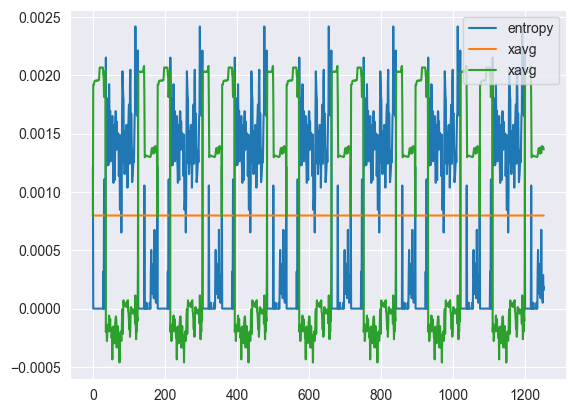

In [43]:
entropiesX = []
user_id = 1610
for ii, row in df_act.loc[user_id].filter(regex=r"X\d+").iterrows():
    entropiesX.append(stats.entropy(row))
    
plt.plot(entropiesX / np.sum(entropiesX), label="entropy")
# res = df_act.loc[user_id, "RESULTANT"].reset_index()
# plt.plot(res / res.sum(), label="resultant")
xavg = df_act.loc[user_id, "XAVG"].reset_index()
plt.plot(xavg / xavg.sum(), label="xavg")
plt.legend()

In [49]:
act_entrX = df_act.filter(regex=r"X\d+").apply(stats.entropy, axis=1).groupby("class").mean()
act_entrY = df_act.filter(regex=r"Y\d+").apply(stats.entropy, axis=1).groupby("class").mean()
act_entrZ = df_act.filter(regex=r"Z\d+").apply(stats.entropy, axis=1).groupby("class").mean()

In [50]:
eat_entrX = df_eat.filter(regex=r"X\d+").apply(stats.entropy, axis=1).groupby("class").mean()
eat_entrY = df_eat.filter(regex=r"Y\d+").apply(stats.entropy, axis=1).groupby("class").mean()
eat_entrZ = df_eat.filter(regex=r"Z\d+").apply(stats.entropy, axis=1).groupby("class").mean()

In [54]:
entropies = pd.concat([act_entrX, act_entrY, act_entrZ, 1/3 * (act_entrX + act_entrY + act_entrZ),
           eat_entrX, eat_entrY, eat_entrZ, 1/3 * (eat_entrX + eat_entrY + eat_entrZ)],
          keys=["act_entrX", "act_entrY", "act_entrZ", "act_entr_mean", "eat_entrX", "eat_entrY", "eat_entrZ", "eat_entr_mean",])
entropies.to_frame().to_parquet("data/entropies.parquet")

### Spectral/temporal

<Axes: >

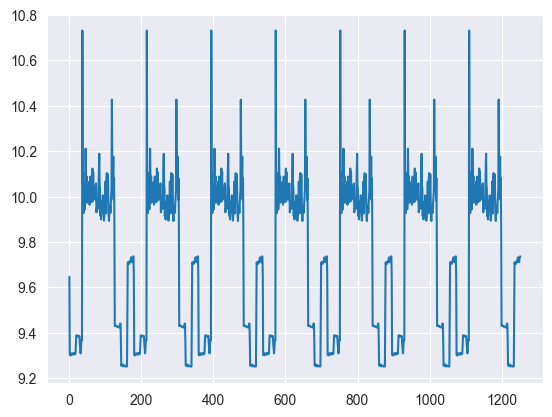

In [79]:
df_act.loc[user_id].reset_index()["RESULTANT"].plot()

<Axes: >

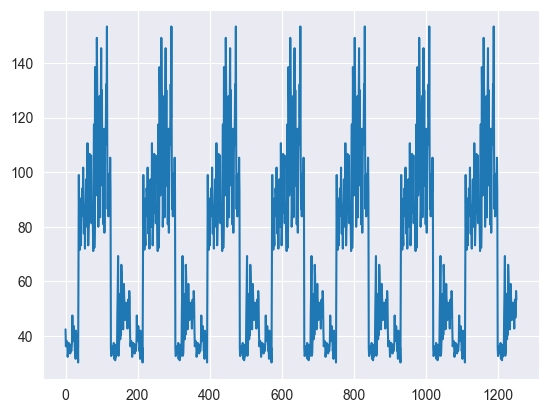

In [80]:
df_act.loc[user_id].reset_index()["XPEAK"].plot()

<Axes: >

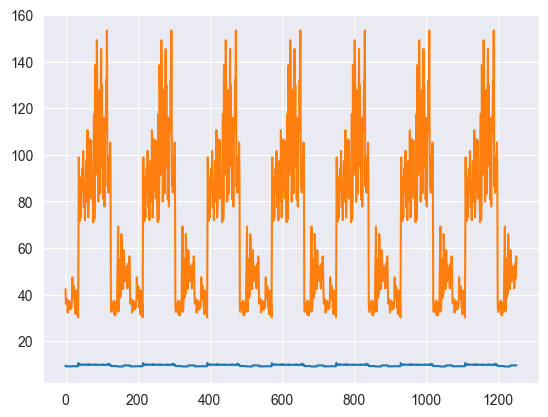

In [78]:
# df_act.loc[user_id].reset_index()["YPEAK"].plot()
# df_act.loc[user_id].reset_index()["ZPEAK"].plot()

MFCC

<Axes: >

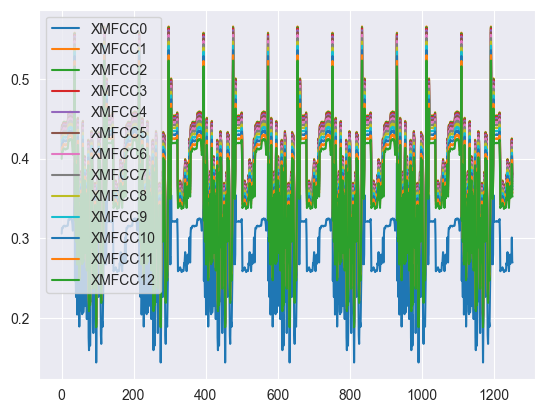

In [82]:
df_act.loc[user_id].reset_index().filter(regex=r"XMFCC\d+").plot()

<Axes: >

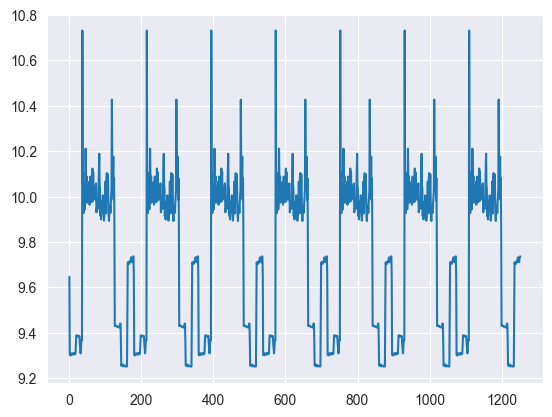

In [83]:
df_act.loc[user_id].reset_index()["RESULTANT"].plot()


Seems again a proxy for the negative of the resultant

**Cosine similarity**

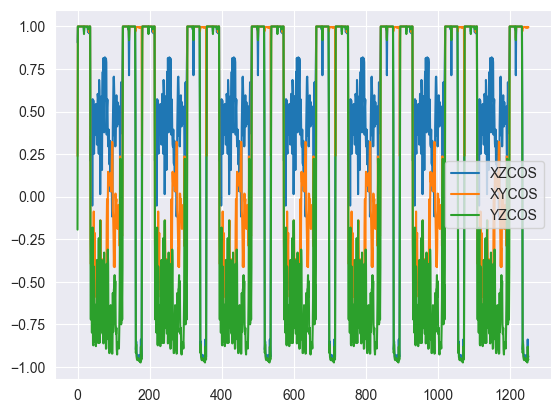

In [86]:
df_act.loc[user_id].reset_index()["XZCOS"].plot()
df_act.loc[user_id].reset_index()["XYCOS"].plot()
df_act.loc[user_id].reset_index()["YZCOS"].plot()
plt.legend()

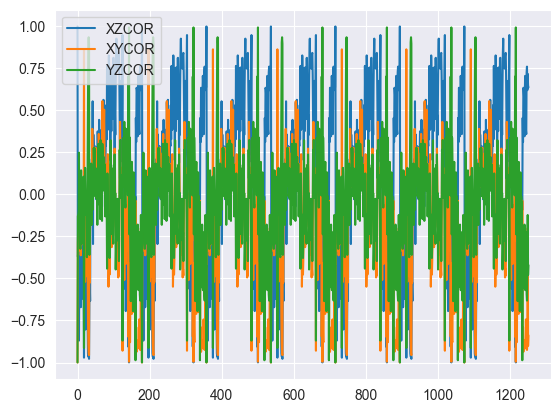

In [87]:
df_act.loc[user_id].reset_index()["XZCOR"].plot()
df_act.loc[user_id].reset_index()["XYCOR"].plot()
df_act.loc[user_id].reset_index()["YZCOR"].plot()
plt.legend()